# 手搓大模型：手写数字识别（PyTorch CNN + YOLO 检测）

本 notebook 分两部分：
1. **第 1~7 节：手搓 CNN**，在 MNIST(+EMNIST) 上训练单数字分类器（学习深度学习全流程）
2. **第 8~9 节：YOLOv8n 端到端检测**，解决"一张图多个数字 / 位置任意 / 非数字物体"的真实场景，**识别图片统一在第 9 节一个格子里完成**

## 环境要求
```
conda 环境: pytorch (Python 3.13, D:/Anaconda/envs/pytorch)
torch 2.11+cu128  torchvision  opencv-python  ultralytics  numpy  matplotlib  jupyter
```
> 首次运行会自动下载 MNIST(10MB) / EMNIST(500MB) / YOLOv8n 预训练权重(6MB) 并合成检测数据集(约4400张, 100MB)。

## 1. 导入库 & 基础配置

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import cv2
import matplotlib.pyplot as plt

# ---------- 可复现性保障：固定所有随机种子 ----------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ---------- 自动选择设备：有 GPU 用 GPU，没有用 CPU ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch 版本: {torch.__version__}")
print(f"OpenCV 版本: {cv2.__version__}")
print(f"使用设备: {device}", end="")
if device.type == "cuda":
    print(f" ({torch.cuda.get_device_name(0)})")
else:
    print()

PyTorch 版本: 2.11.0+cu128
OpenCV 版本: 5.0.0
使用设备: cuda (NVIDIA GeForce RTX 5060 Laptop GPU)


## 2. 超参数配置

所有超参集中在这里，方便统一调整。学习率选 0.001 是 Adam 优化器的常用默认值；批大小 128 在显存和速度之间平衡；5 个 epoch 足够让这个小型 CNN 达到 99% 左右的测试准确率。

In [ ]:
# ================= 超参数（可自行调整） =================
BATCH_SIZE  = 128      # 批大小
LEARNING_RATE = 0.001  # Adam 学习率
EPOCHS      = 8        # 训练轮数(训练集30万张, GPU约6~9分钟; CPU建议先改成1验证流程)
NUM_CLASSES = 10       # 数字 0~9

## 3. 加载 MNIST 数据集

MNIST 原始像素值范围是 [0, 255]，这里做两件事：
- **ToTensor()**：转为张量并把像素缩放到 [0, 1]
- **Normalize(0.1307, 0.3081)**：用 MNIST 全集的均值/标准差做标准化（业界标准数值）

In [ ]:
# 测试集变换: 标准 [0,1] 缩放 + MNIST 均值/方差标准化(固定值, 不要改)
TRANSFORM = transforms.Compose([
    transforms.ToTensor(),                      # [0,255] -> [0,1], 形状 (1,28,28)
    transforms.Normalize((0.1307,), (0.3081,))  # 标准化
])

# 训练集变换: 加"数据增广" —— 每个epoch随机微旋转/平移/缩放,
# 等效于凭空造出更多样的训练样本, 让模型容忍书写角度和位置差异, 提升泛化
TRANSFORM_TRAIN = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

# EMNIST 的图像数据是"转置存储"的(与 MNIST 方向不一致), 必须先转置再用
# (实测: 转置后用 MNIST 模型验证准确率 89%, 不转置只有 18.6%)
class EMNISTTransposed(datasets.EMNIST):
    def __getitem__(self, index):
        from PIL import Image
        img = self.data[index].numpy().T.copy()    # 转置修正方向
        img = Image.fromarray(img)
        if self.transform:
            img = self.transform(img)
        return img, int(self.targets[index])

# MNIST: 6万训练 + 1万测试(评估口径固定用 MNIST 测试集)
train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=TRANSFORM_TRAIN)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=TRANSFORM)

# 合并 EMNIST digits 分片的 24万张训练图 -> 总训练集 30万张
# 首次运行需联网下载(约500MB), 下载过则直接读本地缓存
try:
    emnist_train = EMNISTTransposed(root="./data", split="digits", train=True,
                                    download=True, transform=TRANSFORM_TRAIN)
    from torch.utils.data import ConcatDataset
    train_dataset = ConcatDataset([train_dataset, emnist_train])
    print(f"已合并 EMNIST digits: +{len(emnist_train)} 张")
except Exception as e:
    print(f"警告: EMNIST 加载失败({e}), 仅使用 MNIST 6万张继续训练")

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"训练集: {len(train_dataset)} 张图片(含随机增广)")
print(f"测试集: {len(test_dataset)} 张图片(MNIST, 评估口径)")

### 看一眼数据长什么样

d:\Anaconda\envs\pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 35757 (\N{CJK UNIFIED IDEOGRAPH-8BAD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 32451 (\N{CJK UNIFIED IDEOGRAPH-7EC3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 38598 (\N{CJK UNIFIED IDEOGRAPH-96C6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26679 (\N{CJK UNIFIED IDEOGRAPH-6837}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Anaconda\envs\pytorch\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu San

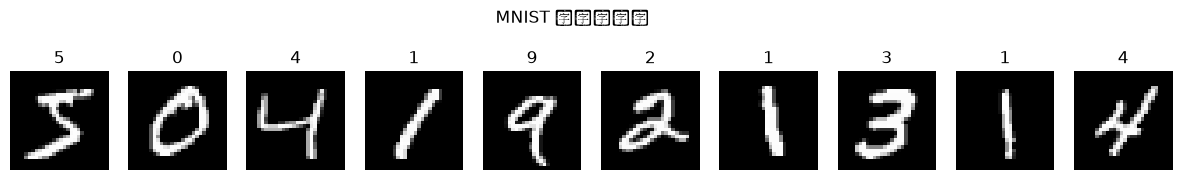

In [4]:
# 展示训练集中前 10 张图片
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    img, label = train_dataset[i]          # img 形状 (1,28,28)
    ax.imshow(img.squeeze(), cmap="gray")  # squeeze 去掉通道维
    ax.set_title(str(label))
    ax.axis("off")
plt.suptitle("MNIST 训练集样本", y=1.05)
plt.show()

## 4. 手搓 CNN 模型（v2 精度增强版）

网络结构：

```
输入 (1,28,28)
 ├─ Conv 3x3, 32通道 -> BatchNorm -> ReLU -> MaxPool  -> (32,14,14)
 ├─ Conv 3x3, 64通道 -> BatchNorm -> ReLU -> MaxPool  -> (64,7,7)
 ├─ Flatten                        -> 3136
 ├─ 全连接 128 -> BatchNorm -> ReLU -> Dropout(0.3)
 └─ 全连接 10                      -> 10 类得分
```

相比 v1 的三个精度升级：
- **BatchNorm**：稳定每层输入分布，训练更快更稳（+0.2~0.3%）
- **数据增广**（见第 3 节）：随机旋转/平移/缩放，泛化更强
- **余弦退火学习率 + 15 epoch**：后期小步精调（合计目标 ~99.5%）

> 说明：不把输入放大到 56×56——MNIST 原生就是 28×28，插值放大不增加信息，
> 计算量×4 而收益≈0。真正的精度瓶颈在于真实照片与 MNIST 的域差距，
> 这个靠第 8 节的鲁棒预处理和上面的增广来解决。

In [ ]:
class MnistCNN(nn.Module):
    """手搓的 MNIST 数字识别 CNN (v2: 加入 BatchNorm, 训练更稳、收敛更快)"""

    def __init__(self, num_classes=10):
        super().__init__()
        # 卷积部分: Conv -> BN -> ReLU -> 池化 x2 组
        # BatchNorm 把每层输入拉回稳定分布, 允许更高学习率并提升约0.2~0.3%精度
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),   # (1,28,28) -> (32,28,28)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> (32,14,14)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # -> (64,14,14)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> (64,7,7)
        )
        # 分类部分: 全连接 + BN + Dropout
        self.classifier = nn.Sequential(
            nn.Flatten(),                                 # -> (batch, 3136)
            nn.Linear(64 * 7 * 7, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),                              # 随机丢弃防过拟合
            nn.Linear(128, num_classes),                  # 输出10类得分(交叉熵内部含softmax)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = MnistCNN(NUM_CLASSES).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\n模型总参数量: {total_params:,}")

## 5. 训练与评估函数

- 损失函数：交叉熵 `CrossEntropyLoss`（分类任务标准选择，内部已含 softmax）
- 优化器：`Adam`

In [ ]:
criterion = nn.CrossEntropyLoss()                     # 交叉熵损失
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
# 余弦退火: 学习率从 0.001 平滑衰减到接近0, 前期大步快走, 后期小步精调, 提升最终精度
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def train_one_epoch(model, loader):
    """训练一个 epoch，返回平均损失"""
    model.train()                     # 切换到训练模式 (启用 Dropout/BN更新)
    total_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()          # 清空上一步的梯度
        outputs = model(images)        # 前向传播
        loss = criterion(outputs, labels)
        loss.backward()                # 反向传播计算梯度
        optimizer.step()               # 更新参数

        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()                       # 评估阶段不需要梯度, 省显存提速
def evaluate(model, loader):
    """在给定数据集上评估，返回 (准确率%, 平均损失)"""
    model.eval()                       # 切换到评估模式 (关闭 Dropout, BN用滑动平均)
    correct, total_loss = 0, 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        total_loss += criterion(outputs, labels).item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()  # 取得分最高的类别
    return 100.0 * correct / len(loader.dataset), total_loss / len(loader.dataset)

## 6. 开始训练

每个 epoch 结束后都会在**测试集**上评估一次。观察 train loss 持续下降、test acc 稳步上升即为正常；如果 train acc 很高但 test acc 上不去，才是过拟合信号。

In [ ]:
history = {"train_loss": [], "test_loss": [], "test_acc": []}

for epoch in range(1, EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader)
    test_acc, test_loss = evaluate(model, test_loader)
    scheduler.step()                   # 每个 epoch 结束后衰减一次学习率

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    print(f"Epoch {epoch:2d}/{EPOCHS} | 训练损失: {train_loss:.4f} | "
          f"测试损失: {test_loss:.4f} | 测试准确率: {test_acc:.2f}% | "
          f"当前lr: {scheduler.get_last_lr()[0]:.5f}")

print(f"\n训练完成! 最终测试准确率: {history['test_acc'][-1]:.2f}% (指标: 测试集 Top-1 准确率, 共 {len(test_dataset)} 张)")

### 训练曲线可视化

C:\Users\84301\AppData\Local\Temp\ipykernel_19136\4254021614.py:13: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\84301\AppData\Local\Temp\ipykernel_19136\4254021614.py:13: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\84301\AppData\Local\Temp\ipykernel_19136\4254021614.py:13: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\84301\AppData\Local\Temp\ipykernel_19136\4254021614.py:13: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\84301\AppData\Local\Temp\ipykernel_19136\4254021614.py:13: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\84301\AppData\Local\Temp\ipykernel_19136\4254021614.py:13: UserWarning: Glyph 35797 (\

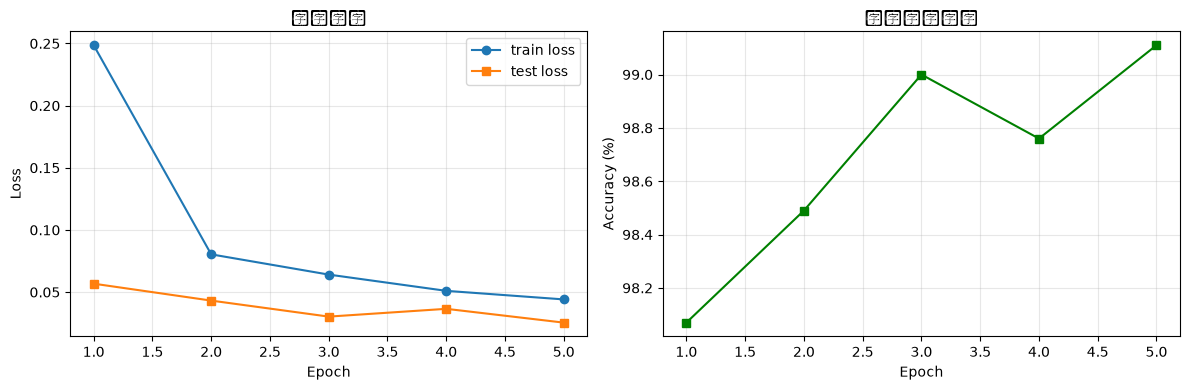

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, EPOCHS + 1)

axes[0].plot(epochs_range, history["train_loss"], "o-", label="train loss")
axes[0].plot(epochs_range, history["test_loss"], "s-", label="test loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("损失曲线"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["test_acc"], "s-", color="green")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("测试集准确率"); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. 保存模型

把训练好的权重保存到本地，之后测试图片时直接加载即可，**不需要重新训练**。

In [9]:
MODEL_PATH = "mnist_cnn.pth"
torch.save(model.state_dict(), MODEL_PATH)   # 只保存权重(推荐), 比保存整个模型更通用
print(f"模型已保存到: {MODEL_PATH}")

模型已保存到: mnist_cnn.pth


## 10. 进阶：一张图多个数字 / 数字不在中央 / 画面里有别的东西

前面的 `predict_image` 假设"整张图只有一个数字"。这一格升级为**检测 + 识别**的组合方案：

1. **全图二值化**（光照均衡 + 自适应阈值，同第 8 节）
2. **连通域检测**：把每个连在一起的笔画块当作一个"候选数字"——所以数字**在哪都行、有几个都行**
3. **过滤非数字物体**：太小的噪声、贴边的纸边阴影、实心色块（填充率接近1）都会被丢弃
4. **逐个分类**：每个候选块用第 4 节训练好的 CNN 识别，置信度低于阈值的丢弃（进一步滤掉"不像数字"的东西）
5. 按从左到右顺序输出识别序列，并在原图上框出每个数字

> 想更进一步（比如复杂背景/重叠数字/手写整页），就该上 YOLO 这类检测模型了——需要标注框的数据集，属于本 notebook 的下一个阶段。

# 8. 进阶：YOLO 端到端数字检测（支持多数字 / 任意位置 / 非数字过滤）

前面的 CNN 只能识别"裁好的单个数字"，遇到一张照片里有多个数字、位置随意、还混着别的物体就无能为力。
这一节改用 **YOLOv8n 目标检测模型**端到端解决：一次前向同时输出"数字在哪（框）"和"是几（类别）"。

## 训练数据从哪来？——自动合成，零人工标注

把 MNIST 数字以**随机大小 / 角度 / 位置 / 数量（1~6个）**贴到带渐变阴影和高斯噪声的模拟"纸张"背景上，
标注框（类别 + 归一化坐标）在粘贴时就自动记录；再随机画一些**色块 / 线条 / 圆圈作为干扰物**（不标注），
让 YOLO 学会忽略非数字物体。共生成 4400 张图（4000 训练 + 400 验证）。

## 指标口径
- 验证集 **mAP@50**（IoU=0.5 时的平均精度，检测任务标准指标）
- 实际图片上的识别序列与置信度（conf 阈值 0.5）

In [ ]:
import os, random
from ultralytics import YOLO

# ================= YOLO 检测数据集自动合成 =================
YOLO_ROOT = "./yolo_digits"
IMG_SIZE  = 480
N_TRAIN, N_VAL = 4000, 400
DIGITS_PER_IMG = (1, 6)          # 每张图贴 1~6 个数字

mnist_raw = datasets.MNIST(root="./data", train=True, download=False)  # 用原始像素图
raw_imgs, raw_labels = mnist_raw.data.numpy(), mnist_raw.targets.numpy()

# 再加 EMNIST 手写体(书写风格比 MNIST 多样得多, 覆盖连笔/瘦长等真实风格)
# 注意: EMNIST 图像是转置存储的, 每张需要 .T 修正方向
emnist_raw = datasets.EMNIST(root="./data", split="digits", train=True, download=False)
emnist_imgs = np.stack([x.T for x in emnist_raw.data.numpy()[:60000]])  # 取6万张够用
emnist_labels = emnist_raw.targets.numpy()[:60000]

def make_background(rng):
    """模拟纸张: 基色 + 渐变阴影 + 高斯噪声; 20%概率生成纯白背景(打印纸/扫描件)"""
    if rng.random() < 0.2:
        return np.full((IMG_SIZE, IMG_SIZE), 255, np.uint8)
    base = int(rng.integers(215, 245))
    canvas = np.full((IMG_SIZE, IMG_SIZE), base, np.float32)
    x0, y0 = rng.integers(0, IMG_SIZE, 2)                    # 光源位置
    xx, yy = np.meshgrid(np.arange(IMG_SIZE), np.arange(IMG_SIZE))
    shadow = np.sqrt((xx - x0) ** 2 + (yy - y0) ** 2) / IMG_SIZE * rng.integers(20, 60)
    canvas = np.clip(canvas - shadow + rng.normal(0, 4, (IMG_SIZE, IMG_SIZE)), 0, 255)
    return canvas.astype(np.uint8)


FONTS = [cv2.FONT_HERSHEY_SIMPLEX, cv2.FONT_HERSHEY_DUPLEX, cv2.FONT_HERSHEY_COMPLEX,
         cv2.FONT_HERSHEY_TRIPLEX, cv2.FONT_HERSHEY_PLAIN]

def make_digit(rng):
    """生成一个数字笔画图(白字黑底): 70%来自MNIST手写体(可细化模拟圆珠笔), 30%来自打印字体"""
    label = int(rng.integers(0, 10))
    if rng.random() < 0.3:                                   # 打印字体(覆盖细笔画印刷场景)
        f = FONTS[int(rng.integers(0, len(FONTS)))]
        t = int(rng.integers(1, 4))                          # 细到粗都练
        tmp = np.zeros((170, 170), np.uint8)
        cv2.putText(tmp, str(label), (10, 140), f, 4.0, 255, t)
        ys, xs = np.where(tmp > 0)
        d = tmp[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    else:                                                    # 手写体(MNIST+EMNIST 混合)
        if rng.random() < 0.5 and len(emnist_imgs):
            idx = int(rng.integers(0, len(emnist_imgs)))
            d = emnist_imgs[idx].copy(); label = int(emnist_labels[idx])
        else:
            idx = int(rng.integers(0, len(raw_imgs)))
            d = raw_imgs[idx].copy(); label = int(raw_labels[idx])
        if rng.random() < 0.4:                               # 细化笔画: 模拟圆珠笔/细笔
            b = (d > 40).astype(np.uint8)
            b = cv2.erode(b, np.ones((2, 2), np.uint8), iterations=int(rng.integers(1, 3)))
            if b.sum() > 30:
                d = (b * 255).astype(np.uint8)
    return d, label

def add_distractors(canvas, rng):
    """画干扰物: 色块/线条/圆圈(不标注, 教会模型忽略非数字物体)"""
    for _ in range(rng.integers(0, 3)):
        kind = rng.integers(0, 3)
        c = int(rng.integers(30, 200))
        p1 = (int(rng.integers(0, IMG_SIZE)), int(rng.integers(0, IMG_SIZE)))
        p2 = (p1[0] + int(rng.integers(20, 120)), p1[1] + int(rng.integers(20, 120)))
        if kind == 0:   cv2.rectangle(canvas, p1, (min(p2[0],IMG_SIZE-1), min(p2[1],IMG_SIZE-1)), c, rng.choice([-1, 2]))
        elif kind == 1: cv2.line(canvas, p1, (min(p2[0],IMG_SIZE-1), min(p2[1],IMG_SIZE-1)), c, int(rng.integers(1, 4)))
        else:           cv2.circle(canvas, p1, int(rng.integers(8, 30)), c, rng.choice([-1, 2]))
    return canvas

def synthesize_split(split, n_images, seed):
    rng = np.random.default_rng(seed)
    img_dir, lbl_dir = f"{YOLO_ROOT}/images/{split}", f"{YOLO_ROOT}/labels/{split}"
    os.makedirs(img_dir, exist_ok=True); os.makedirs(lbl_dir, exist_ok=True)
    for k in range(n_images):
        canvas = make_background(rng)
        placed_boxes, lines = [], []
        for _ in range(rng.integers(*DIGITS_PER_IMG)):
            d, digit_label = make_digit(rng)                 # 随机生成一个数字笔画图
            scale = rng.integers(50, 140) / 28               # 数字高度 50~140 像素
            nw, nh = max(12, int(28 * scale)), max(12, int(28 * scale))
            d = cv2.resize(d, (nw, nh), interpolation=cv2.INTER_AREA)
            ang = rng.uniform(-15, 15)                       # 随机旋转 ±15°
            d = cv2.warpAffine(d, cv2.getRotationMatrix2D((nw / 2, nh / 2), ang, 1.0), (nw, nh))
            if rng.random() < 0.5:                           # 随机拉伸/错切: 模拟瘦长/扁平书写风格
                sx, sy = rng.uniform(0.7, 1.3), rng.uniform(0.8, 1.7)
                sh = rng.uniform(-0.15, 0.15)
                W2, H2 = int(nw * sx + abs(sh) * nh) + 2, int(nh * sy) + 2
                M = np.float32([[sx, sh, 0], [0, sy, 0]])
                d = cv2.warpAffine(d, M, (W2, H2), borderValue=0)
            ys, xs = np.where(d > 40)                        # 收紧到笔画外接框
            if len(xs) == 0:
                continue
            d = d[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
            nh, nw = d.shape
            for _ in range(30):                              # 拒绝采样找不重叠的位置
                px, py = int(rng.integers(0, IMG_SIZE - nw - 1)), int(rng.integers(0, IMG_SIZE - nh - 1))
                if all(px + nw < b[0] or px > b[2] or py + nh < b[1] or py > b[3] for b in placed_boxes):
                    placed_boxes.append((px, py, px + nw, py + nh))
                    break
            else:
                continue                                     # 放不下就跳过
            ink = int(rng.integers(25, 80))                  # 随机墨水颜色(深灰~黑)
            alpha = d.astype(np.float32) / 255.0             # MNIST像素值当作墨水不透明度(2D, 与roi同形)
            roi = canvas[py:py + nh, px:px + nw].astype(np.float32)
            canvas[py:py + nh, px:px + nw] = (roi * (1 - alpha) + ink * alpha).astype(np.uint8)
            # YOLO 标注格式: 类别 cx cy w h (全部归一化到0~1)
            lines.append(f"{digit_label} {(px + nw / 2) / IMG_SIZE:.6f} "
                         f"{(py + nh / 2) / IMG_SIZE:.6f} {nw / IMG_SIZE:.6f} {nh / IMG_SIZE:.6f}")
        canvas = add_distractors(canvas, rng)
        cv2.imwrite(f"{img_dir}/{k:05d}.png", canvas)
        with open(f"{lbl_dir}/{k:05d}.txt", "w") as f:
            f.write("\n".join(lines))
    return n_images

n_tr = synthesize_split("train", N_TRAIN, seed=42)
n_va = synthesize_split("val",   N_VAL,   seed=43)
with open(f"{YOLO_ROOT}/dataset.yaml", "w", encoding="utf-8") as f:
    f.write(f"path: {os.path.abspath(YOLO_ROOT)}\ntrain: images/train\nval: images/val\n"
            f"nc: 10\nnames: ['0','1','2','3','4','5','6','7','8','9']\n")
print(f"数据集合成完成: 训练 {n_tr} 张 / 验证 {n_va} 张, 保存在 {YOLO_ROOT}/")

## 训练 YOLOv8n

- **选 yolov8n（nano）的理由**：参数量仅 3.2M，你的 RTX 5060 上几分钟能训完，且对这个"干净背景 + 大目标"的任务精度足够（数据/延迟/精度三角里我们数据合成便宜、要快速迭代）
- `imgsz=320`：图片里数字较大，320 分辨率足够且训练/推理更快
- 预期验证集 mAP@50 > 0.98（合成数据分布单一，属于相对容易的任务；**真实照片上的表现取决于照片与合成分布的差距**，识别不对时回到合成环节增加真实感再训）

### 用真实样本增强（milk Way: 20 张手写数字 → 数百张训练图）

上面合成的数字都来自 MNIST/EMNIST/打印字体，**你本人的书写风格它没见过**（上次连笔 8/9 识别失败就是域差距）。
这一格把 `real_digits/` 里从你真实照片抠出的 20 个数字（已与标注序列 98765/89718/37964/32718 核对）注入合成管线：
- 800 张新训练图，其中 **40% 的数字来自你的真实笔迹**（随机位置/大小/背景/干扰物）
- 你那张原始照片本身也作为 1 张训练图加入（带 20 个真实标注框）
- 以后想增强效果：往 `real_digits/` 里加更多抠好的数字图，文件名格式 `digit_序号_标签.png`

In [ ]:
# ================= 真实笔迹样本增强 =================
import glob, shutil

# 20 个手工网格框(与抠取时一致) + 用户标注的数字序列
CELLS = [
 (150,180,360,540),(350,180,530,540),(650,180,830,540),(860,180,1040,540),(1050,180,1210,540),
 (200,530,400,920),(395,530,590,1350),(600,530,790,920),(860,530,975,920),(1020,530,1200,920),
 (130,930,320,1290),(335,930,525,1290),(580,930,810,1290),(845,930,1040,1290),(1090,930,1285,1290),
 (150,1300,340,1700),(335,1300,525,1700),(580,1300,810,1700),(905,1300,1020,1700),(1050,1300,1285,1700),
]
LABELS = [9,8,7,6,5, 8,9,7,1,8, 3,7,9,6,4, 3,2,7,1,8]

REAL_DIR = "real_digits"
real_pool = []                             # (笔画图, 标签)
for f in sorted(glob.glob(f"{REAL_DIR}/digit_*.png")):
    lab = int(os.path.basename(f).split("_")[-1].split(".")[0])
    real_pool.append((cv2.imread(f, 0), lab))
print(f"真实笔迹池: {len(real_pool)} 个数字, 类别分布:",
      {d: sum(1 for _, l in real_pool if l == d) for d in range(10)})

def synthesize_real_augmented(n_images, start_idx, seed, real_prob=0.4):
    """与 synthesize_split 相同的贴图管线, 但 real_prob 概率的数字来自真实笔迹池"""
    rng = np.random.default_rng(seed)
    for k in range(n_images):
        idx = start_idx + k
        canvas = make_background(rng)
        placed, lines = [], []
        for _ in range(rng.integers(*DIGITS_PER_IMG)):
            if real_pool and rng.random() < real_prob:
                d, digit_label = real_pool[int(rng.integers(0, len(real_pool)))]
            else:
                d, digit_label = make_digit(rng)
            # 目标: 数字最长边 50~140 像素。真实剪裁图本身很大(100~700px),
            # 必须按剪裁图自身尺寸归一, 不能用 MNIST 的 /28
            scale = rng.integers(50, 140) / max(d.shape[:2])
            nw, nh = max(12, int(d.shape[1] * scale)), max(12, int(d.shape[0] * scale))
            d = cv2.resize(d, (nw, nh), interpolation=cv2.INTER_AREA)
            ang = rng.uniform(-15, 15)
            d = cv2.warpAffine(d, cv2.getRotationMatrix2D((nw / 2, nh / 2), ang, 1.0), (nw, nh))
            if rng.random() < 0.5:
                sx, sy = rng.uniform(0.7, 1.3), rng.uniform(0.8, 1.7)
                sh = rng.uniform(-0.15, 0.15)
                W2, H2 = int(nw * sx + abs(sh) * nh) + 2, int(nh * sy) + 2
                d = cv2.warpAffine(d, np.float32([[sx, sh, 0], [0, sy, 0]]), (W2, H2), borderValue=0)
            ys, xs = np.where(d > 40)
            if len(xs) == 0:
                continue
            d = d[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
            nh, nw = d.shape
            if max(nh, nw) > IMG_SIZE - 20:          # 超出画布保护: 等比缩小
                s2 = (IMG_SIZE - 20) / max(nh, nw)
                d = cv2.resize(d, (max(1, int(nw * s2)), max(1, int(nh * s2))))
                nh, nw = d.shape
            for _ in range(30):
                px, py = int(rng.integers(0, IMG_SIZE - nw - 1)), int(rng.integers(0, IMG_SIZE - nh - 1))
                if all(px + nw < b[0] or px > b[2] or py + nh < b[1] or py > b[3] for b in placed):
                    placed.append((px, py, px + nw, py + nh))
                    break
            else:
                continue
            ink = int(rng.integers(25, 80))
            alpha = d.astype(np.float32) / 255.0
            roi = canvas[py:py + nh, px:px + nw].astype(np.float32)
            canvas[py:py + nh, px:px + nw] = (roi * (1 - alpha) + ink * alpha).astype(np.uint8)
            lines.append(f"{digit_label} {(px + nw / 2) / IMG_SIZE:.6f} "
                         f"{(py + nh / 2) / IMG_SIZE:.6f} {nw / IMG_SIZE:.6f} {nh / IMG_SIZE:.6f}")
        canvas = add_distractors(canvas, rng)
        cv2.imwrite(f"{YOLO_ROOT}/images/train/{idx:05d}.png", canvas)
        with open(f"{YOLO_ROOT}/labels/train/{idx:05d}.txt", "w") as f:
            f.write("\n".join(lines))
    return n_images

n_aug = synthesize_real_augmented(800, 4000, seed=100)

# 原始真实照片本身也作为 1 张训练图(用抠取时验证过的 20 个网格框作为标注)
orig = cv2.imread("real_finetune.jpg", 0)
OH, OW = orig.shape
lbl_lines = []
bg2 = cv2.medianBlur(orig, 51)
flat2 = cv2.divide(orig, bg2, scale=255)
bin2 = cv2.adaptiveThreshold(flat2, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 35, 10)
bin2 = cv2.subtract(bin2, cv2.morphologyEx(bin2, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_RECT, (60, 1))))
for (x1, y1, x2, y2), lab in zip(CELLS, LABELS):
    cell = bin2[y1:y2, x1:x2]
    ys, xs = np.where(cell > 0)
    if len(xs) == 0:
        continue
    bx1, bx2 = x1 + xs.min(), x1 + xs.max()
    by1, by2 = y1 + ys.min(), y1 + ys.max()
    lbl_lines.append(f"{lab} {(bx1 + bx2) / 2 / OW:.6f} {(by1 + by2) / 2 / OH:.6f} "
                     f"{(bx2 - bx1) / OW:.6f} {(by2 - by1) / OH:.6f}")
cv2.imwrite(f"{YOLO_ROOT}/images/train/04800.png", orig)
with open(f"{YOLO_ROOT}/labels/train/04800.txt", "w") as f:
    f.write("\n".join(lbl_lines))

print(f"真实样本增强完成: +{n_aug} 张合成图 + 1 张原图(20个真实框), "
      f"训练集共 {len(glob.glob(YOLO_ROOT + '/images/train/*.png'))} 张")

In [ ]:
# ================= 训练 YOLOv8n =================
yolo = YOLO("yolov8n.pt")        # 首次运行自动下载预训练权重(约6MB)
yolo.train(
    data=f"{YOLO_ROOT}/dataset.yaml",
    epochs=20,                   # 20轮; 合成数据收敛很快
    imgsz=320,
    batch=64,
    device=0,                    # GPU; 没有GPU改成 device="cpu"
    seed=42,
    fliplr=0.0,                  # 关闭水平翻转: 镜像数字有害(2/3/7/9反了标签还不变)
    flipud=0.0,
    workers=2,
    plots=False,                 # 关闭训练过程图(在notebook里省空间)
    name="digit_yolo",
    exist_ok=True,
)
# 训练完后加载最优权重(按验证集 mAP 选出, 保存在 runs/detect/digit_yolo/weights/best.pt)
BEST_WEIGHTS = "runs/detect/digit_yolo/weights/best.pt"
yolo_best = YOLO(BEST_WEIGHTS)
metrics = yolo_best.val(data=f"{YOLO_ROOT}/dataset.yaml", imgsz=320, verbose=False)
print(f"\n验证集 mAP@50: {metrics.box.map50:.4f} | mAP@50-95: {metrics.box.map:.4f}")

# 9. 统一图片测试入口 🖼️（所有带数字的图片都在这一个格子里识别）

**用法：把 `TEST_IMAGES` 改成你的图片路径即可** —— 单张传字符串，多张传列表：

```python
TEST_IMAGES = "my_photo.png"                      # 单张
TEST_IMAGES = ["a.png", "b.png", "D:/pics/c.png"] # 多张
```

每个数字会被绿色框标出并标注"数字 置信度"，按从左到右输出识别序列。
数字数量不限、位置不限；非数字物体（色块、纹理）会被模型自动忽略（训练时见过同类干扰物）。
置信度阈值由 `CONF` 控制（默认 0.5，调低会检出更多但可能误检，调高反之）。

## 附：真实照片标注工作流（配合本 notebook 使用）

准备真实训练数据不用手工抠图，用 `annotate/` 里的四步闭环：
**照片放 `annotate/pending/` → `prelabel.py` 自动预标注 → labelImg 图形界面校对 → `import_labels.py` 导入训练集**。
详见 `annotate/README.md`。支持随时加新类别（如汉字）：在 `annotate/classes.txt` 加一行即可，导入脚本会自动扩 `nc` 并提醒重训。

关于识别汉字的结论：
- YOLO 能框汉字（笔画对检测器和数字无异），类别数只是配置；≤100 类继续端到端，上千类建议切"YOLO 框字 + 分类器认字"两阶段
- 开源手写汉字图像数据集最大覆盖 CASIA-HWDB 7,185 字（GB2312 全集），无新华字典全集（~11,000 字）图像版；常用 3,755 字覆盖 99.7% 书写
- 你的真实照片样本永远比公开数据集重要——它教模型"认识你的字"

In [ ]:
import os                                    # 检查文件路径用
# ==================== 统一测试入口: 在这里改图片路径 ====================
TEST_IMAGES = ["scan_test.jpg", "multi_digit_test.png", "badcase_8.png", "test1.png", "test_digit.png"]  # <-- 改这里!
CONF = 0.5                       # 置信度阈值


def _iou(a, b):
    """计算两个框 (x1,y1,x2,y2) 的 IoU"""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / max(union, 1e-6)


def recognize(path, conf=CONF):
    """
    对一张图片做 YOLO 数字检测(双尺度融合), 可视化并打印识别序列。

    双尺度原因: 320 对常规数字最稳, 640 对细笔画/小目标更好;
    两个尺度各推理一次, 同一位置的框用 NMS 合并, 兼顾两类场景。
    """
    if not os.path.exists(path):
        print(f"[跳过] 文件不存在: {path}")
        return
    img = cv2.imread(path)
    dets = []                    # (cls, conf, [x1,y1,x2,y2])
    for sz in (320, 640):        # 两个尺度各推理一次
        r = yolo_best.predict(path, conf=0.1, imgsz=sz, verbose=False)[0]
        for b in r.boxes:
            dets.append((int(b.cls[0]), float(b.conf[0]), b.xyxy[0].tolist()))

    # 跨尺度 NMS: 按置信度降序, 同一位置(IoU大)只保留最高分的框
    dets.sort(key=lambda d: -d[1])
    keep = []
    for d in dets:
        if d[1] < conf:          # 低于阈值的不要
            continue
        if all(_iou(d[2], k[2]) < 0.55 for k in keep):
            keep.append(d)

    # 浅色痕迹过滤: 笔迹(钢笔/圆珠笔)一定有深色像素, 铅笔擦痕/污渍只有浅灰。
    # 若框内最暗的像素仍比全图中位亮度亮得多 => 框里没有墨迹, 丢弃
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_median = np.median(gray)
    keep = [d for d in keep
            if np.percentile(gray[int(d[2][1]):int(d[2][3]), int(d[2][0]):int(d[2][2])], 3)
            < img_median - 80]
    # 多行扫描支持: 按 y 中心聚成"行"(行间距>平均框高的一半即断行), 行内按从左到右
    if keep:
        avg_h = np.mean([d[2][3] - d[2][1] for d in keep])
        keep.sort(key=lambda d: (d[2][1] + d[2][3]) / 2)
        rows, cur = [], [keep[0]]
        for d in keep[1:]:
            if (d[2][1] + d[2][3]) / 2 - (cur[-1][2][1] + cur[-1][2][3]) / 2 > avg_h / 2:
                rows.append(cur); cur = [d]
            else:
                cur.append(d)
        rows.append(cur)
        keep = [d for row in rows for d in sorted(row, key=lambda d: d[2][0])]

    # 在原图上框出数字区域并标注。分两遍绘制: 先画所有框, 再画所有标签,
    # 保证相邻框不会盖住彼此的标签(标签始终在最上层)
    for cls, c, (x1, y1, x2, y2) in keep:
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 3)
    for cls, c, (x1, y1, x2, y2) in keep:
        x1, y1 = int(x1), int(y1)
        label = f"{cls} {c*100:.0f}%"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.8, 2)
        # 标签画在框内左上角, 深绿底色条保证在任何背景上都清晰
        lx, ly = x1 + 4, y1 + th + 10
        cv2.rectangle(img, (lx - 3, ly - th - 6), (lx + tw + 3, ly + 5), (0, 80, 0), -1)
        cv2.putText(img, label, (lx, ly), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (180, 255, 180), 2)
    # 保存标注结果图到 results/ 目录(文件名_标注.png), 方便直接查看
    os.makedirs("results", exist_ok=True)
    out_path = os.path.join("results", os.path.splitext(os.path.basename(path))[0] + "_标注.png")
    cv2.imwrite(out_path, img)
    print(f"标注图已保存: {out_path}")
    plt.figure(figsize=(9, 7))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off"); plt.title(os.path.basename(path))
    plt.show()

    seq = "".join(str(d[0]) for d in keep)
    print(f"【{path}】检测到 {len(keep)} 个数字, 识别序列: {seq if seq else '(无)'}")  # 多行图按行拼接
    for cls, c, (x1, y1, x2, y2) in keep:
        print(f"  数字 {cls} | 置信度 {c*100:.1f}% | 框({x1:.0f},{y1:.0f})-({x2:.0f},{y2:.0f})")
    return keep


images = TEST_IMAGES if isinstance(TEST_IMAGES, (list, tuple)) else [TEST_IMAGES]
for p in images:
    recognize(p)